In [23]:
# Prediction file locations

project_folder = Path(
    r"C:\Users\bobmo\OneDrive\DataScience2"
)

validation_folder = project_folder / "model_validation_predictions"
test_folder = project_folder / "2024_model_predictions"

# 2023 validation predictions
validation_files = {
    "Logistic Regression": validation_folder / "logreg_validation_predictions.parquet",
    "Random Forest": validation_folder / "rf_validation_predictions.parquet",
    "XGBoost": project_folder / "xgb_validation_predictions.parquet"
}

# 2024 final testing predictions
test_files = {
    "Logistic Regression": test_folder / "logreg_test_2024_predictions.parquet",
    "Random Forest": test_folder / "rf_test_2024_predictions.parquet",
    "XGBoost": test_folder / "xgb_test_2024_predictions.parquet"
}

# Verify files
for model in validation_files:
    print(f"\n{model}")
    print("2023:", validation_files[model].exists())
    print("2024:", test_files[model].exists())


Logistic Regression
2023: True
2024: True

Random Forest
2023: True
2024: True

XGBoost
2023: True
2024: True


In [24]:
# Load 2023 validation predictions
# Only load columns needed for model evaluation to reduce memory usage.

logreg_checked = pd.read_parquet(
    validation_files["Logistic Regression"],
    columns=["y_true", "y_prob"],
    engine="fastparquet"
)

rf_checked = pd.read_parquet(
    validation_files["Random Forest"],
    columns=["y_true", "y_prob"],
    engine="fastparquet"
)

xgb_checked = pd.read_parquet(
    validation_files["XGBoost"],
    columns=["y_true", "y_prob"],
    engine="fastparquet"
)

# Rename actual-label column for consistency
for predictions in [logreg_checked, rf_checked, xgb_checked]:
    predictions.rename(columns={"y_true": "y_test"}, inplace=True)

# Organize validation predictions
validation_predictions = {
    "Logistic Regression": logreg_checked,
    "Random Forest": rf_checked,
    "XGBoost": xgb_checked
}

# Display dataset information
for model, predictions in validation_predictions.items():
    print(f"\n{model}")
    print("Shape:", predictions.shape)
    print("Columns:", predictions.columns.tolist())


Logistic Regression
Shape: (27655685, 2)
Columns: ['y_test', 'y_prob']

Random Forest
Shape: (27655685, 2)
Columns: ['y_test', 'y_prob']

XGBoost
Shape: (27655685, 2)
Columns: ['y_test', 'y_prob']


In [25]:
# Thresholds agreed with Amsal
thresholds = {
    "Logistic Regression": 0.002,
    "Random Forest": 0.18187,
    "XGBoost": 0.690
}

print("Model thresholds:")
for model, threshold in thresholds.items():
    print(f"{model}: {threshold}")

Model thresholds:
Logistic Regression: 0.002
Random Forest: 0.18187
XGBoost: 0.69


In [26]:
# 2023 Validation Performance Evaluation

results_2023 = []

for model, df in validation_predictions.items():

    threshold = thresholds[model]

    y_true = df["y_test"]
    y_prob = df["y_prob"]
    y_pred = (y_prob >= threshold).astype(int)

    results_2023.append({
        "Model": model,
        "Threshold": threshold,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1 Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Average Precision": average_precision_score(y_true, y_prob)
    })

results_2023 = pd.DataFrame(results_2023)

display(results_2023.round(6).style.hide(axis="index"))

Model,Threshold,Precision,Recall,F1 Score,ROC-AUC,Average Precision
Logistic Regression,0.002000,0.009942,0.666303,0.019592,0.964564,0.010470
Random Forest,0.181870,0.407310,0.549891,0.467981,0.992233,0.449292
XGBoost,0.690000,0.308760,0.564068,0.399074,0.948203,0.267280


In [27]:
# Display final 2023 validation results

display(results_2023.round(6).style.hide(axis="index"))

Model,Threshold,Precision,Recall,F1 Score,ROC-AUC,Average Precision
Logistic Regression,0.002000,0.009942,0.666303,0.019592,0.964564,0.010470
Random Forest,0.181870,0.407310,0.549891,0.467981,0.992233,0.449292
XGBoost,0.690000,0.308760,0.564068,0.399074,0.948203,0.267280


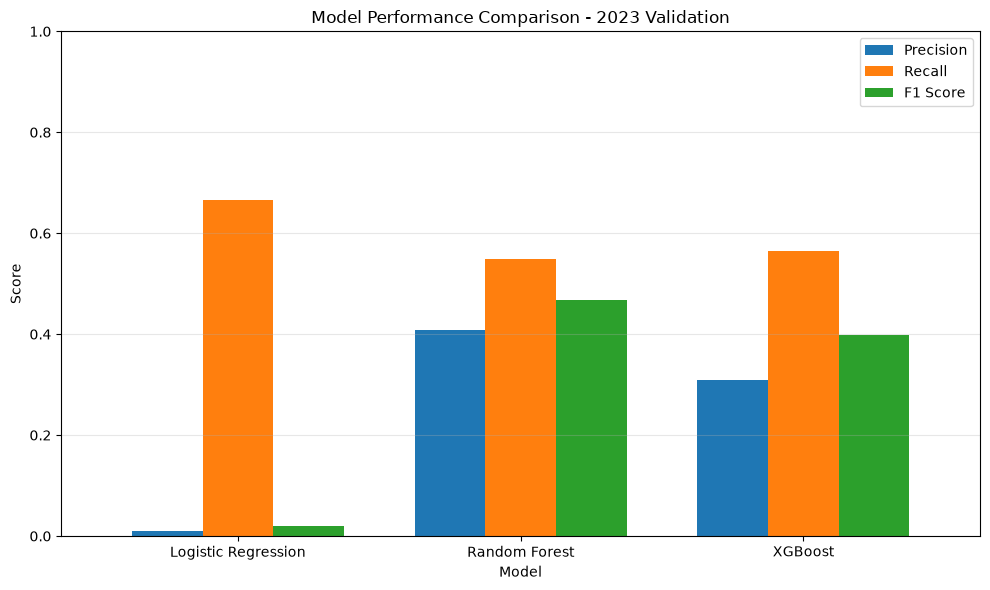

In [28]:
# VALIDATION METRICS COMPARISON

metrics = ["Precision", "Recall", "F1 Score"]

results_2023.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Model Performance Comparison - 2023 Validation")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

C:\Users\bobmo\AppData\Local\Temp\ipykernel_32532\1582709274.py:20: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\bobmo\Anaconda3\envs\tensorflow\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


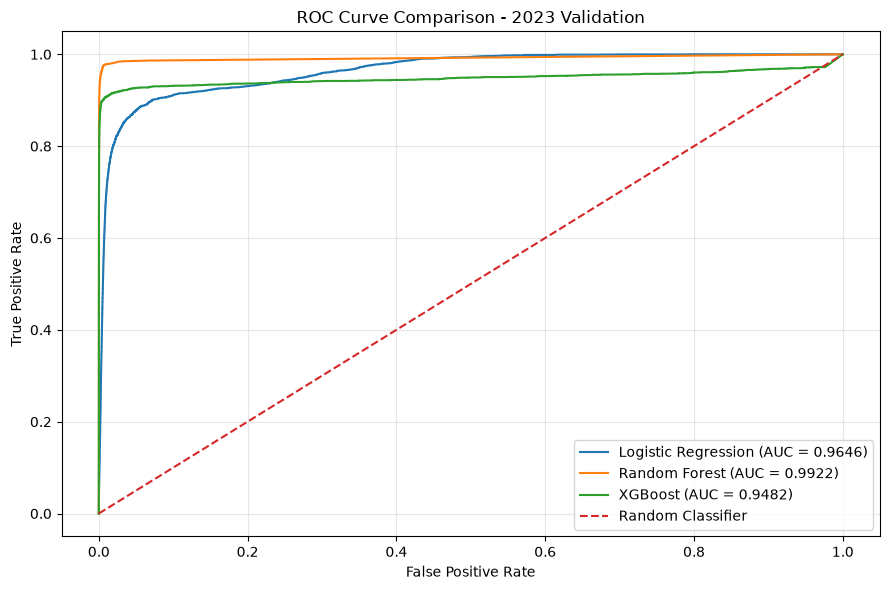

In [29]:
#ROC Curve Comparison
plt.figure(figsize=(9, 6))

for model, df in validation_predictions.items():
    y_true = df["y_test"]
    y_prob = df["y_prob"]

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)

    plt.plot(fpr, tpr, label=f"{model} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison - 2023 Validation")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\bobmo\AppData\Local\Temp\ipykernel_32532\296270929.py:18: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\bobmo\Anaconda3\envs\tensorflow\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


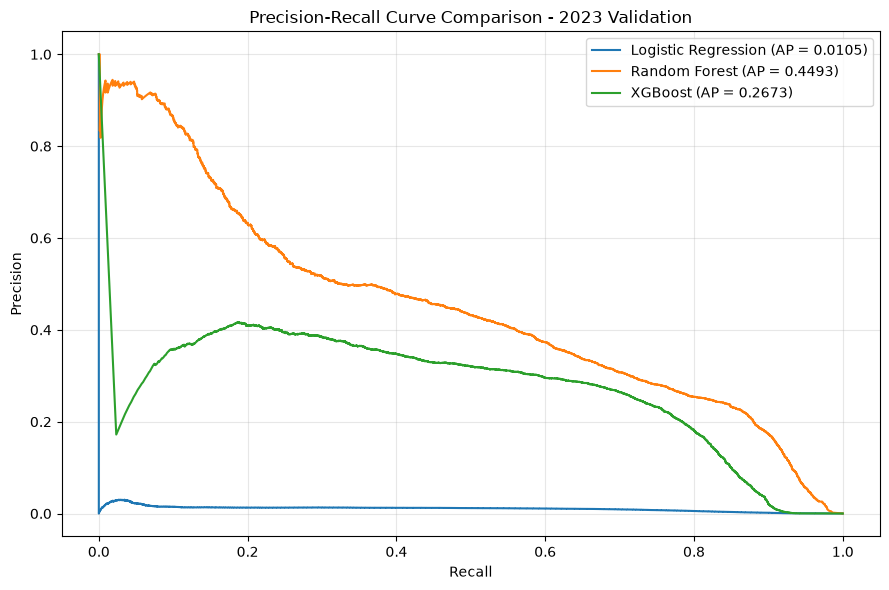

In [30]:
# Precision-Recall Curve Comparison
plt.figure(figsize=(9, 6))

for model, df in validation_predictions.items():
    y_true = df["y_test"]
    y_prob = df["y_prob"]

    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)

    plt.plot(recall, precision, label=f"{model} (AP = {ap:.4f})")

plt.title("Precision-Recall Curve Comparison - 2023 Validation")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
import gc

# Delete large datasets only if they exist
variables_to_clear = [
    "validation_predictions",
    "logreg_checked",
    "rf_checked",
    "xgb_checked",
    "logreg_test",
    "rf_test",
    "xgb_test"
]

for variable in variables_to_clear:
    if variable in globals():
        del globals()[variable]

gc.collect()

print("Memory cleanup completed.")

Memory cleanup completed.


In [32]:
# Load only the necessary columns to reduce memory usage
logreg_test = pd.read_parquet(
    test_files["Logistic Regression"],
    columns=["y_true", "y_prob"],
    engine="fastparquet"
)

rf_test = pd.read_parquet(
    test_files["Random Forest"],
    columns=["y_true", "y_prob"],
    engine="fastparquet"
)

xgb_test = pd.read_parquet(
    test_files["XGBoost"],
    columns=["y_true", "y_prob"],
    engine="fastparquet"
)

# Rename actual labels
for df in [logreg_test, rf_test, xgb_test]:
    df.rename(columns={"y_true": "y_test"}, inplace=True)

# Organize predictions
test_predictions = {
    "Logistic Regression": logreg_test,
    "Random Forest": rf_test,
    "XGBoost": xgb_test
}

for model, df in test_predictions.items():
    print(f"{model}: {df.shape}")

print("\n2024 test predictions loaded successfully.")

Logistic Regression: (27731454, 2)
Random Forest: (27731454, 2)
XGBoost: (27731454, 2)

2024 test predictions loaded successfully.


In [33]:
# Data Quality Checks
# Before evaluating the models, we verify the 2024 test predictions for missing values, duplicate observations, valid probability ranges, and class distribution.

for model, df in test_predictions.items():
    print(f"\n{model}")
    print("-" * 40)

    print("Total observations:", len(df))
    print("Positive observations:", (df["y_test"] == 1).sum())
    print("Negative observations:", (df["y_test"] == 0).sum())
    print("Missing values:", df.isnull().sum().sum())
    print("Probability range:",
          df["y_prob"].min(), "to", df["y_prob"].max())


Logistic Regression
----------------------------------------
Total observations: 27731454
Positive observations: 3843
Negative observations: 27727611
Missing values: 0
Probability range: 6.809684e-09 to 0.29644576

Random Forest
----------------------------------------
Total observations: 27731454
Positive observations: 3843
Negative observations: 27727611
Missing values: 0
Probability range: 0.0 to 0.570361589867758

XGBoost
----------------------------------------
Total observations: 27731454
Positive observations: 3843
Negative observations: 27727611
Missing values: 0
Probability range: 3.006636e-39 to 1.0


In [34]:
# Final Model Performance Evaluation
# Evaluate all three models on the unseen 2024 test dataset using the fixed thresholds selected during 2023 validation. We calculate accuracy, precision, recall, F1-score, ROC-AUC, and Average Precision.

results_2024 = []

for model, df in test_predictions.items():
    threshold = thresholds[model]

    y_true = df["y_test"]
    y_prob = df["y_prob"]
    y_pred = (y_prob >= threshold).astype(int)

    results_2024.append({
        "Model": model,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred,zero_division=0),
        "Recall": recall_score(y_true, y_pred,zero_division=0),
        "F1 Score": f1_score(y_true, y_pred,zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "Average Precision": average_precision_score(y_true, y_prob)
    })

results_2024 = pd.DataFrame(results_2024)

display(results_2024.round(6).style.hide(axis="index"))

Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
Logistic Regression,0.002000,0.992084,0.011183,0.641946,0.021983,0.965714,0.011955
Random Forest,0.181870,0.999832,0.418922,0.543846,0.473279,0.990964,0.445782
XGBoost,0.690000,0.999784,0.332920,0.558678,0.417217,0.945847,0.270442



Logistic Regression - Threshold: 0.002
[[27509471   218140]
 [    1376     2467]]
True Negatives:  27,509,471
False Positives: 218,140
False Negatives: 1,376
True Positives:  2,467


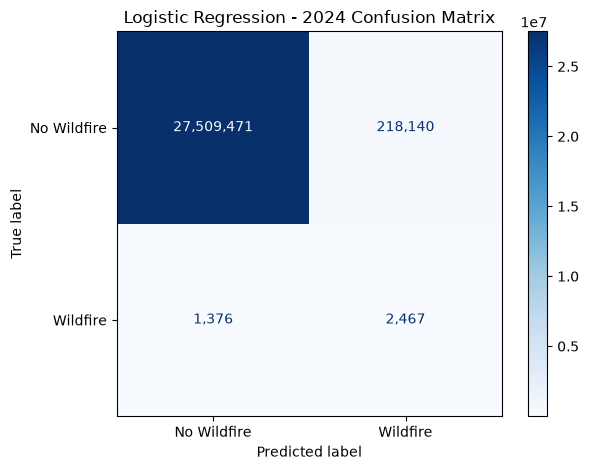


Random Forest - Threshold: 0.18187
[[27724712     2899]
 [    1753     2090]]
True Negatives:  27,724,712
False Positives: 2,899
False Negatives: 1,753
True Positives:  2,090


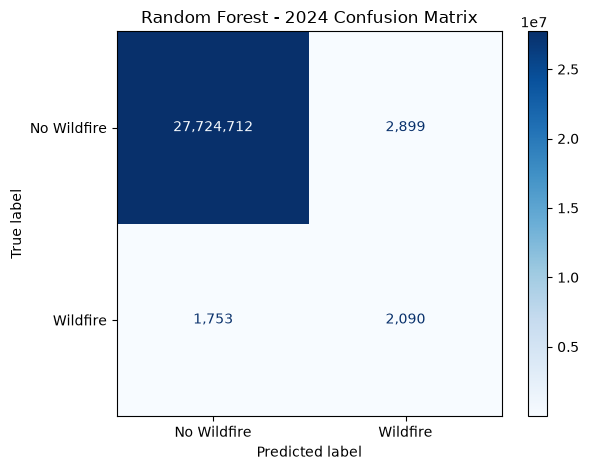


XGBoost - Threshold: 0.69
[[27723309     4302]
 [    1696     2147]]
True Negatives:  27,723,309
False Positives: 4,302
False Negatives: 1,696
True Positives:  2,147


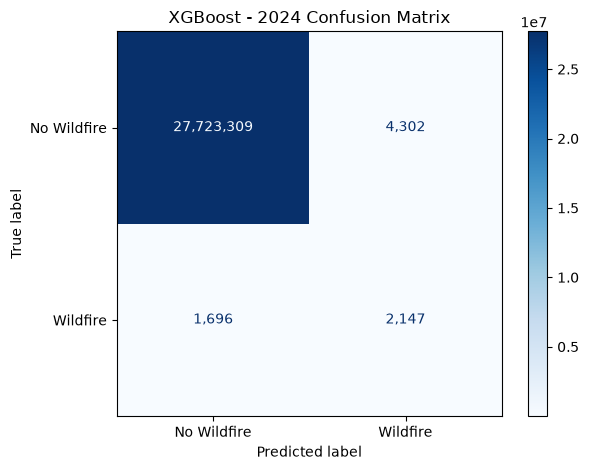

In [35]:
# Confusion Matrix Analysis
# Compare actual and predicted wildfire observations for each model.

from sklearn.metrics import ConfusionMatrixDisplay

for model, df in test_predictions.items():

    threshold = thresholds[model]

    y_true = df["y_test"]
    y_pred = (df["y_prob"] >= threshold).astype(int)

    cm = confusion_matrix(y_true, y_pred)

    tn, fp, fn, tp = cm.ravel()

    print(f"\n{model} - Threshold: {threshold}")
    print(cm)
    print(f"True Negatives:  {tn:,}")
    print(f"False Positives: {fp:,}")
    print(f"False Negatives: {fn:,}")
    print(f"True Positives:  {tp:,}")

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Wildfire", "Wildfire"]
    )

    disp.plot(cmap="Blues", values_format=",")
    plt.title(f"{model} - 2024 Confusion Matrix")
    plt.tight_layout()
    plt.show()

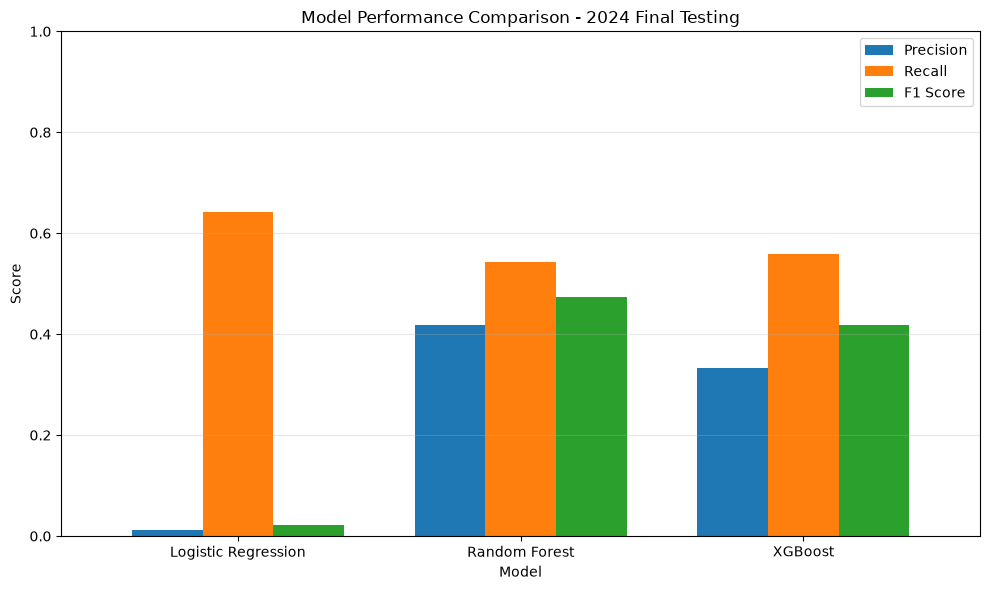

In [36]:
# Model Performance Visualizations
# Comparison of Precision, Recall, and F1-score

# Compare Precision, Recall, and F1-score on 2024 test data

metrics = ["Precision", "Recall", "F1 Score"]

results_2024.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Model Performance Comparison - 2024 Final Testing")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

C:\Users\bobmo\AppData\Local\Temp\ipykernel_32532\1810217936.py:21: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\bobmo\Anaconda3\envs\tensorflow\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


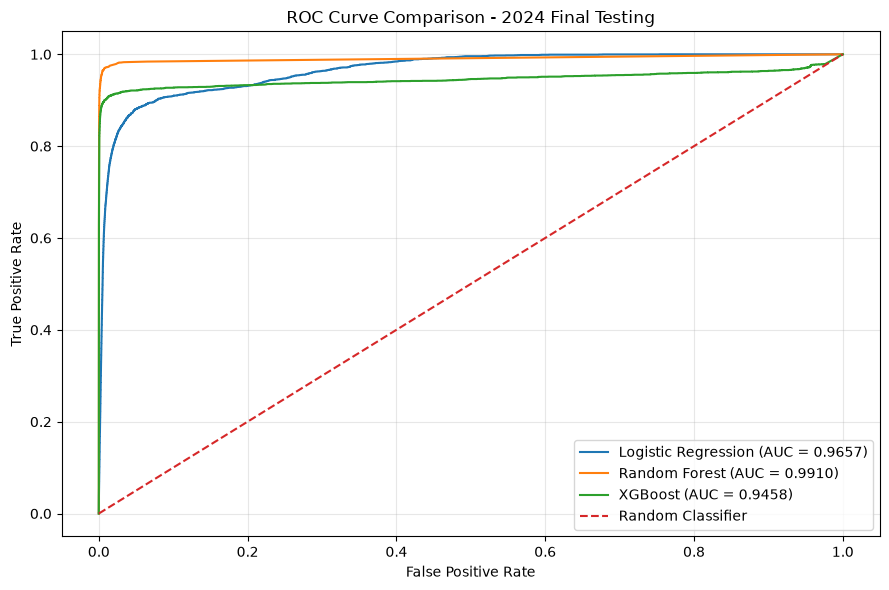

In [37]:
# ROC Curve Comparison

plt.figure(figsize=(9, 6))

for model, df in test_predictions.items():
    y_true = df["y_test"]
    y_prob = df["y_prob"]

    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)

    plt.plot(fpr, tpr, label=f"{model} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curve Comparison - 2024 Final Testing")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\bobmo\AppData\Local\Temp\ipykernel_32532\2848518531.py:19: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
C:\Users\bobmo\Anaconda3\envs\tensorflow\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


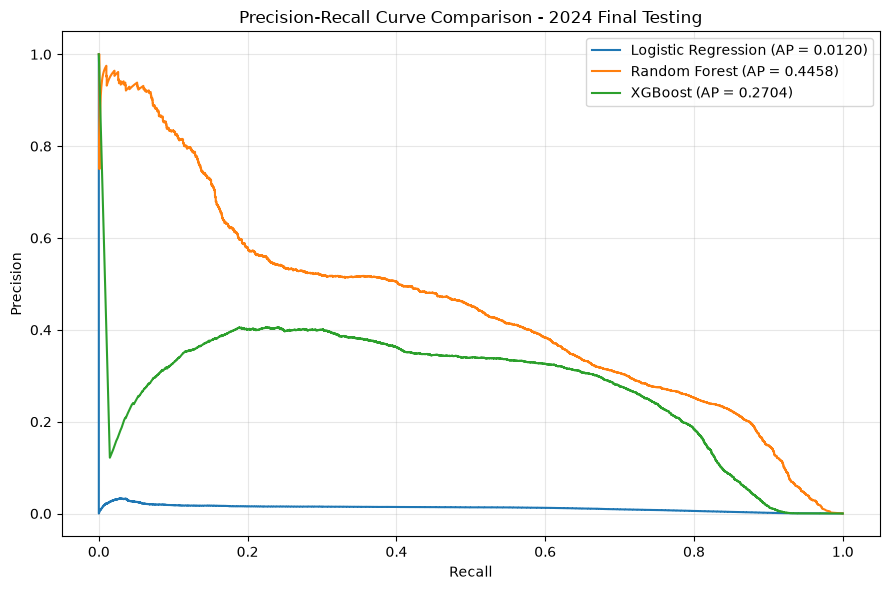

In [38]:
# Precision-Recall Curve Comparison

plt.figure(figsize=(9, 6))

for model, df in test_predictions.items():
    y_true = df["y_test"]
    y_prob = df["y_prob"]

    precision, recall, _ = precision_recall_curve(y_true, y_prob)
    ap = average_precision_score(y_true, y_prob)

    plt.plot(recall, precision, label=f"{model} (AP = {ap:.4f})")

plt.title("Precision-Recall Curve Comparison - 2024 Final Testing")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [39]:
print("2023 results type:", type(results_2023))
print("2023 results shape:", results_2023.shape)
print("2023 columns:", results_2023.columns.tolist())

display(results_2023.head())

2023 results type: <class 'pandas.DataFrame'>
2023 results shape: (3, 7)
2023 columns: ['Model', 'Threshold', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC', 'Average Precision']


,Model,Threshold,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Logistic Regression,0.00200,0.009942,0.666303,0.019592,0.964564,0.010470
1,Random Forest,0.18187,0.407310,0.549891,0.467981,0.992233,0.449292
2,XGBoost,0.69000,0.308760,0.564068,0.399074,0.948203,0.267280


In [40]:
# Comparison Between 2023 Validation and 2024 Final Testing
# This section compares model performance between the 2023 validation dataset and the unseen 2024 test dataset. The comparison helps assess model consistency and generalization across different years.

# Select the evaluation metrics for both years
metrics = [
    "Model",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC",
    "Average Precision"
]

# Prepare 2023 and 2024 results
comparison_2023 = results_2023[metrics].copy()
comparison_2024 = results_2024[metrics].copy()

# Merge both years
comparison = comparison_2023.merge(
    comparison_2024,
    on="Model",
    suffixes=("_2023", "_2024")
)

# Display comparison
display(comparison.round(6).style.hide(axis="index"))

Model,Precision_2023,Recall_2023,F1 Score_2023,ROC-AUC_2023,Average Precision_2023,Precision_2024,Recall_2024,F1 Score_2024,ROC-AUC_2024,Average Precision_2024
Logistic Regression,0.009942,0.666303,0.019592,0.964564,0.010470,0.011183,0.641946,0.021983,0.965714,0.011955
Random Forest,0.407310,0.549891,0.467981,0.992233,0.449292,0.418922,0.543846,0.473279,0.990964,0.445782
XGBoost,0.308760,0.564068,0.399074,0.948203,0.267280,0.332920,0.558678,0.417217,0.945847,0.270442


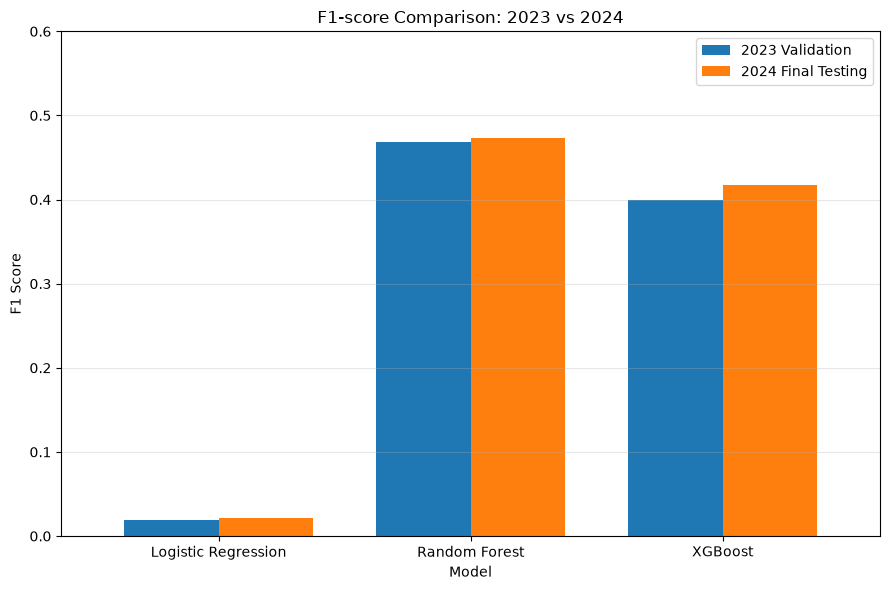

In [41]:
# F1-score Comparison Between 2023 and 2024

f1_comparison = comparison[
    ["Model", "F1 Score_2023", "F1 Score_2024"]
].set_index("Model")

f1_comparison.plot(
    kind="bar",
    figsize=(9, 6),
    width=0.75
)

plt.title("F1-score Comparison: 2023 vs 2024")
plt.ylabel("F1 Score")
plt.xlabel("Model")
plt.ylim(0, 0.6)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(["2023 Validation", "2024 Final Testing"])
plt.tight_layout()
plt.show()

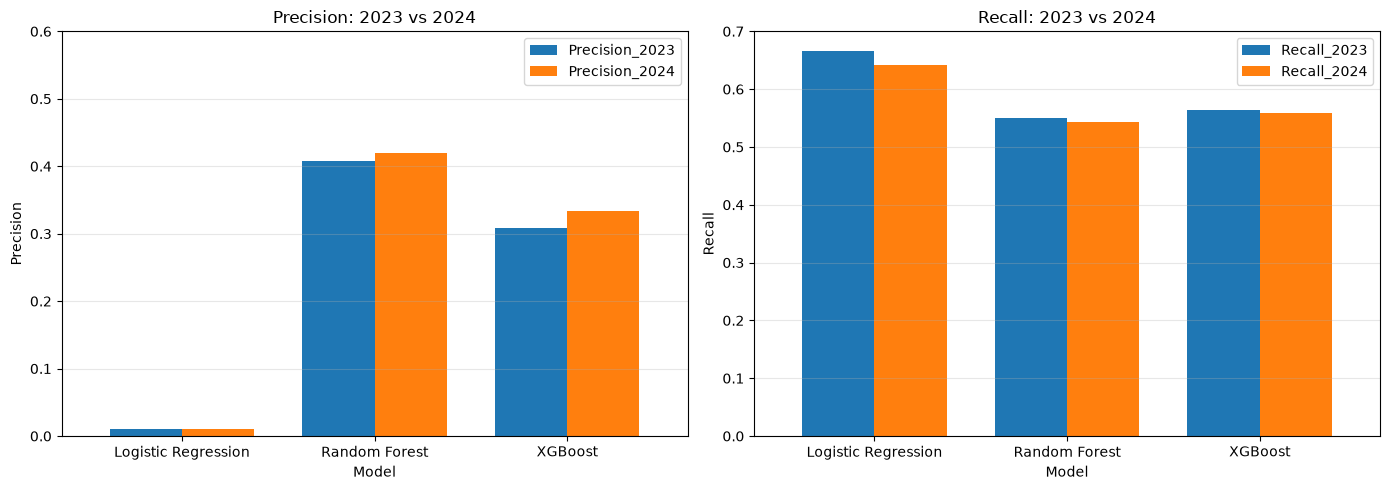

In [42]:
# Precision and Recall Comparison Between 2023 and 2024

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Precision comparison
comparison.set_index("Model")[
    ["Precision_2023", "Precision_2024"]
].plot(kind="bar", ax=axes[0], width=0.75)

axes[0].set_title("Precision: 2023 vs 2024")
axes[0].set_ylabel("Precision")
axes[0].set_ylim(0, 0.6)
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)

# Recall comparison
comparison.set_index("Model")[
    ["Recall_2023", "Recall_2024"]
].plot(kind="bar", ax=axes[1], width=0.75)

axes[1].set_title("Recall: 2023 vs 2024")
axes[1].set_ylabel("Recall")
axes[1].set_ylim(0, 0.7)
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

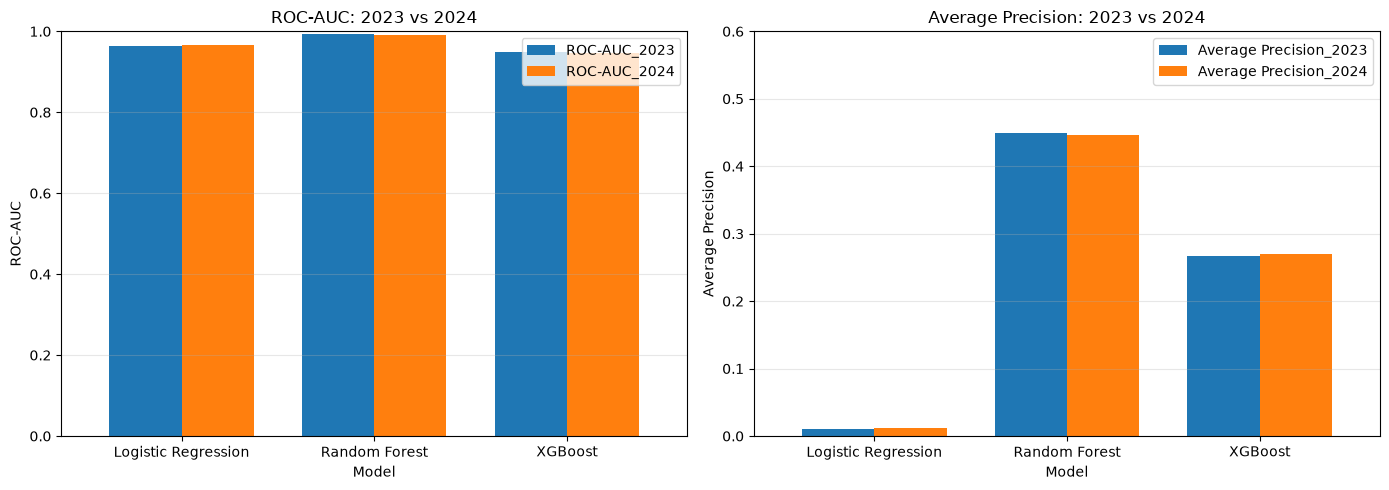

In [43]:
# ROC-AUC and Average Precision Comparison

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC-AUC comparison
comparison.set_index("Model")[
    ["ROC-AUC_2023", "ROC-AUC_2024"]
].plot(kind="bar", ax=axes[0], width=0.75)

axes[0].set_title("ROC-AUC: 2023 vs 2024")
axes[0].set_ylabel("ROC-AUC")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)
axes[0].grid(axis="y", alpha=0.3)

# Average Precision comparison
comparison.set_index("Model")[
    ["Average Precision_2023", "Average Precision_2024"]
].plot(kind="bar", ax=axes[1], width=0.75)

axes[1].set_title("Average Precision: 2023 vs 2024")
axes[1].set_ylabel("Average Precision")
axes[1].set_ylim(0, 0.6)
axes[1].tick_params(axis="x", rotation=0)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [44]:
# Final Conclusions
# The evaluation compared Logistic Regression, Random Forest, and XGBoost using 2023 validation data and unseen 2024 test data. Random Forest achieved the strongest overall performance, maintaining the highest F1-score, ROC-AUC, and Average Precision in both years. Logistic Regression achieved the highest recall, making it useful when detecting as many wildfire ignition events as possible is the priority, although it produced substantially more false positives. XGBoost provided competitive performance, ranking between Logistic Regression and Random Forest across several metrics.
#
# Overall, Random Forest is the recommended model because it provides the best balance between precision and recall while maintaining consistent performance across both years. These results demonstrate its potential for wildfire prediction, although further improvements are needed to reduce false alarms and missed wildfire observations.